## Dawn Andrei Pamesa and Alba
## TS31

Imports

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, ShuffleSplit, cross_val_score, GridSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from skopt import BayesSearchCV
from skopt.space import Integer

Loading the Dataset

In [2]:
df = pd.read_csv("Boston-1.csv", index_col=0)
print("Shape :", df.shape)
df.head()

Shape : (506, 14)


,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,black,lstat,medv
1,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
2,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
3,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
4,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
5,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2


Check Missing Values

In [3]:
print(df.isnull().sum())

crim       0
zn         0
indus      0
chas       0
nox        0
rm         0
age        0
dis        0
rad        0
tax        0
ptratio    0
black      0
lstat      0
medv       0
dtype: int64


Checking if the Target is Balanced

A regression target has no classes, so balance is checked by cutting `medv` (median house value) into five equal-width price ranges and counting the rows in each range. Skewness is also computed.

In [4]:
print("Skewness of medv :", round(df["medv"].skew(), 4))
df["medv"].describe()

Skewness of medv : 1.1081


count    506.000000
mean      22.532806
std        9.197104
min        5.000000
25%       17.025000
50%       21.200000
75%       25.000000
max       50.000000
Name: medv, dtype: float64

In [5]:
price_ranges = pd.cut(df["medv"], bins=5)
range_counts = price_ranges.value_counts().sort_index()

balance = pd.DataFrame({
    "Rows": range_counts,
    "Percent": (range_counts / len(df) * 100).round(1),
})
balance

,Rows,Percent
medv,,
"(4.955, 14.0]",77,15.2
"(14.0, 23.0]",239,47.2
"(23.0, 32.0]",123,24.3
"(32.0, 41.0]",36,7.1
"(41.0, 50.0]",31,6.1


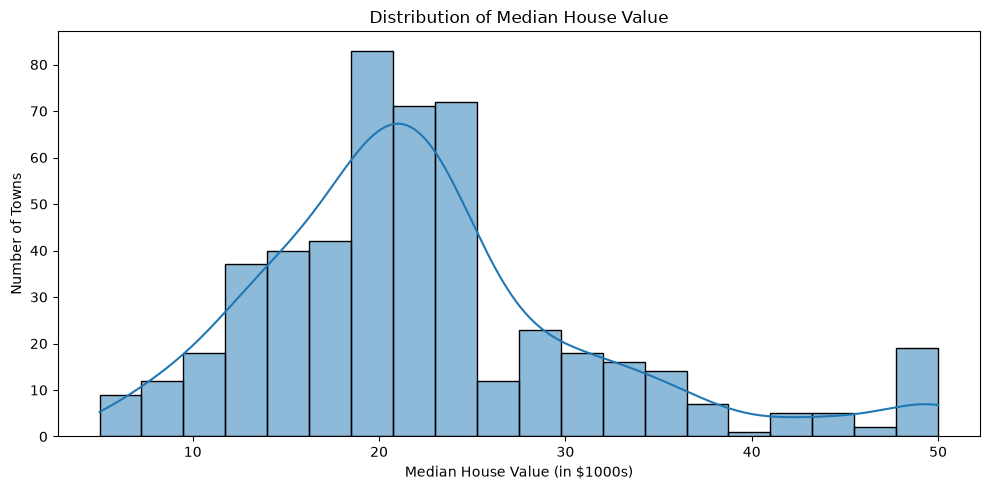

In [6]:
plt.figure(figsize=(10, 5))
sns.histplot(df["medv"], bins=20, kde=True)
plt.title("Distribution of Median House Value")
plt.xlabel("Median House Value (in $1000s)")
plt.ylabel("Number of Towns")
plt.tight_layout()
plt.show()

The target is imbalanced. Median house value has a skewness of 1.1081, so it leans to the right. Almost half of the towns (47.2%) fall in the 14.0 to 23.0 range, while only 6.1% fall in the 41.0 to 50.0 range, so cheap and average houses are well represented and expensive houses are rare. Because of this, the stratified method is used for tuning below.

Selecting Features and Target

In [7]:
X = df.drop(columns="medv")
y = df["medv"]

Splitting the Data

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 379
Testing rows: 127


Selecting the Regression Model

Random Forest Regressor is used because it handles the mix of features in this dataset without scaling and has several hyperparameters to tune.

In [9]:
rf = RandomForestRegressor(random_state=42)

K-Fold Cross-Validation

In [10]:
kfold = KFold(n_splits=5, shuffle=True, random_state=42)
kfold_scores = cross_val_score(rf, X_train, y_train, cv=kfold, scoring="r2")

print("K-Fold R² scores :", kfold_scores.round(4))
print("Mean R²          :", round(kfold_scores.mean(), 4))
print("Std of R²        :", round(kfold_scores.std(), 4))

K-Fold R² scores : [0.7913 0.8568 0.8782 0.8694 0.8091]
Mean R²          : 0.841
Std of R²        : 0.0344


Stratified Cross-Validation

Stratified folds need class labels, so the training prices are cut into five groups with the same number of rows (`pd.qcut`). Each fold then keeps the same mix of cheap and expensive houses.

In [11]:
y_train_groups = pd.qcut(y_train, q=5, labels=False)
print(y_train_groups.value_counts().sort_index())

medv
0    76
1    76
2    78
3    73
4    76
Name: count, dtype: int64


In [12]:
skfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
stratified_splits = list(skfold.split(X_train, y_train_groups))
stratified_scores = cross_val_score(rf, X_train, y_train, cv=stratified_splits, scoring="r2")

print("Stratified R² scores :", stratified_scores.round(4))
print("Mean R²              :", round(stratified_scores.mean(), 4))
print("Std of R²            :", round(stratified_scores.std(), 4))

Stratified R² scores : [0.8334 0.765  0.9309 0.8363 0.8187]
Mean R²              : 0.8369
Std of R²            : 0.0536


Shuffle Split

In [13]:
shuffle = ShuffleSplit(n_splits=5, test_size=0.2, random_state=42)
shuffle_scores = cross_val_score(rf, X_train, y_train, cv=shuffle, scoring="r2")

print("Shuffle Split R² scores :", shuffle_scores.round(4))
print("Mean R²                 :", round(shuffle_scores.mean(), 4))
print("Std of R²               :", round(shuffle_scores.std(), 4))

Shuffle Split R² scores : [0.7949 0.832  0.8699 0.8561 0.7594]
Mean R²                 : 0.8225
Std of R²               : 0.0405


Comparing the Three Validation Methods

In [14]:
cv_results = pd.DataFrame({
    "Method": ["K-Fold", "Stratified K-Fold", "Shuffle Split"],
    "Mean R²": [kfold_scores.mean(), stratified_scores.mean(), shuffle_scores.mean()],
    "Std of R²": [kfold_scores.std(), stratified_scores.std(), shuffle_scores.std()],
}).round(4)

cv_results

,Method,Mean R²,Std of R²
0,K-Fold,0.8410,0.0344
1,Stratified K-Fold,0.8369,0.0536
2,Shuffle Split,0.8225,0.0405


Grid Search

Three hyperparameters are tuned: `n_estimators` (number of trees), `max_depth` (how deep each tree can grow) and `min_samples_split` (rows needed to split a node). The stratified folds are used for scoring because the target is not evenly spread.

In [15]:
param_grid = {
    "n_estimators": [50, 100, 200],
    "max_depth": [5, 10, None],
    "min_samples_split": [2, 5, 10],
}

grid_search = GridSearchCV(RandomForestRegressor(random_state=42), param_grid, cv=stratified_splits, scoring="r2", n_jobs=-1)
grid_search.fit(X_train, y_train)

print("Best parameters  :", grid_search.best_params_)
print("Best CV R²       :", round(grid_search.best_score_, 4))

Best parameters  : {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 50}
Best CV R²       : 0.8436


Bayesian Optimization

Bayesian search tries 20 combinations and uses the earlier scores to choose the next one, over the same three hyperparameters with a range instead of a fixed list.

In [16]:
search_space = {
    "n_estimators": Integer(50, 300),
    "max_depth": Integer(3, 20),
    "min_samples_split": Integer(2, 20),
}

bayes_search = BayesSearchCV(RandomForestRegressor(random_state=42), search_space, n_iter=20, cv=stratified_splits, scoring="r2", n_jobs=-1, random_state=42)
bayes_search.fit(X_train, y_train)

print("Best parameters  :", dict(bayes_search.best_params_))
print("Best CV R²       :", round(bayes_search.best_score_, 4))

Best parameters  : {'max_depth': 19, 'min_samples_split': 2, 'n_estimators': 50}
Best CV R²       : 0.8438


Predicting with the Three Models

In [17]:
rf.fit(X_train, y_train)
y_pred_default = rf.predict(X_test)

best_grid = grid_search.best_estimator_
y_pred_grid = best_grid.predict(X_test)

best_bayes = bayes_search.best_estimator_
y_pred_bayes = best_bayes.predict(X_test)

Regression Metrics on the Test Set

In [18]:
results = pd.DataFrame({
    "Model": ["Default Random Forest", "Grid Search", "Bayesian Optimization"],
    "R²": [r2_score(y_test, y_pred_default), r2_score(y_test, y_pred_grid), r2_score(y_test, y_pred_bayes)],
    "MAE": [mean_absolute_error(y_test, y_pred_default), mean_absolute_error(y_test, y_pred_grid), mean_absolute_error(y_test, y_pred_bayes)],
    "MSE": [mean_squared_error(y_test, y_pred_default), mean_squared_error(y_test, y_pred_grid), mean_squared_error(y_test, y_pred_bayes)],
})
results["RMSE"] = np.sqrt(results["MSE"])
results = results.round(4)

results

,Model,R²,MAE,MSE,RMSE
0,Default Random Forest,0.8539,2.1421,10.2341,3.1991
1,Grid Search,0.8567,2.1406,10.0360,3.1680
2,Bayesian Optimization,0.8603,2.1377,9.7804,3.1274


Actual vs Predicted House Values

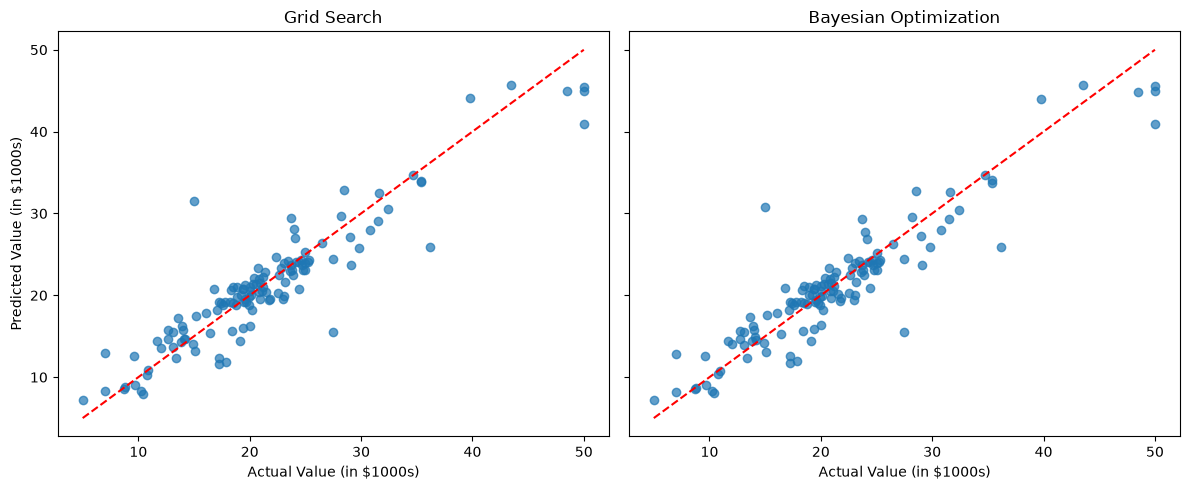

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

for ax, y_pred, name in zip(axes, [y_pred_grid, y_pred_bayes], ["Grid Search", "Bayesian Optimization"]):
    ax.scatter(y_test, y_pred, alpha=0.7)
    ax.plot([y.min(), y.max()], [y.min(), y.max()], color="red", linestyle="--")
    ax.set_title(name)
    ax.set_xlabel("Actual Value (in $1000s)")

axes[0].set_ylabel("Predicted Value (in $1000s)")
plt.tight_layout()
plt.show()

Error by Price Range

In [20]:
test_ranges = pd.cut(y_test, bins=[0, 14, 23, 32, 41, 50])
abs_error = (y_test - y_pred_bayes).abs()

error_by_range = pd.DataFrame({
    "Test Rows": y_test.groupby(test_ranges, observed=True).size(),
    "MAE": abs_error.groupby(test_ranges, observed=True).mean().round(2),
})
error_by_range

,Test Rows,MAE
medv,,
"(0, 14]",22,1.83
"(14, 23]",61,1.90
"(23, 32]",33,2.17
"(32, 41]",6,3.23
"(41, 50]",5,4.89


## Conclusion

Random Forest explained about 84% of the variation in house value in cross-validation (K-Fold 0.8410, Stratified 0.8369, Shuffle Split 0.8225), and the three methods give similar scores, so the result does not depend much on how the training data is split. Tuning helped only a little. On the test set, R² went from 0.8539 for the default model to 0.8567 with grid search and 0.8603 with Bayesian optimization, and RMSE went from 3.1991 to 3.1680 and 3.1274, which is about $3,100 in house value. Both searches picked the smallest number of trees in their range (50) and the smallest split size (2), so the default settings were already close to the best. The models were compared on one test split only, so the 0.0064 gap in R² between the default and Bayesian models is too small to call a clear win. Bayesian optimization used 20 tries against 27 combinations for grid search and ended with almost the same cross-validation score (0.8438 against 0.8436). The target is skewed to the right, and the errors follow it: the average error is about 1.9 for houses in the 14 to 23 range but 4.89 for houses in the 41 to 50 range, where the data has the fewest examples, so predictions for expensive houses are the least reliable.